# Image Stitching & Panorama
Stitching overlapping images with SIFT features, RANSAC homography estimation and perspective warping.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

## Two-image stitching

In [2]:
def detect_and_match(image1, image2, lowe_ratio=0.75):
    sift = cv2.SIFT_create()

    kp1, des1 = sift.detectAndCompute(image1, None)
    kp2, des2 = sift.detectAndCompute(image2, None)

    matcher = cv2.BFMatcher(cv2.NORM_L2)
    all_matches = matcher.knnMatch(des1, des2, k=2)

    # Lowe's ratio test
    good_matches = [m[0] for m in all_matches
                    if len(m) == 2 and m[0].distance < lowe_ratio * m[1].distance]

    pts1 = np.float32([kp1[m.queryIdx].pt for m in good_matches])
    pts2 = np.float32([kp2[m.trainIdx].pt for m in good_matches])

    return pts1, pts2, good_matches, kp1, kp2


def compute_homography(pts1, pts2):
    # maps image 2 into image 1's frame
    H, inlier_mask = cv2.findHomography(pts2, pts1, cv2.RANSAC, 5.0)
    if H is None:
        raise ValueError("Could not estimate a homography - not enough matches")
    return H, inlier_mask


def stitch_and_blend(img1, img2, H):
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]

    canvas_w = w1 + w2
    canvas_h = max(h1, h2)

    warped = cv2.warpPerspective(img2, H, (canvas_w, canvas_h))

    canvas = np.zeros((canvas_h, canvas_w, 3), dtype=np.uint8)
    canvas[0:h1, 0:w1] = img1

    # average the two images where they overlap
    mask1 = (canvas.sum(axis=2) > 0).astype(np.float32)
    mask2 = (warped.sum(axis=2) > 0).astype(np.float32)
    overlap = (mask1 * mask2)[:, :, np.newaxis]

    keep = 1 - overlap * 0.5
    blended = canvas.astype(np.float32) * keep + warped.astype(np.float32) * keep
    blended = np.clip(blended, 0, 255).astype(np.uint8)

    # trim empty columns on the right
    gray = cv2.cvtColor(blended, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 1, 255, cv2.THRESH_BINARY)
    active_cols = np.any(thresh > 0, axis=0)

    return blended[:, :np.max(np.where(active_cols)) + 1]

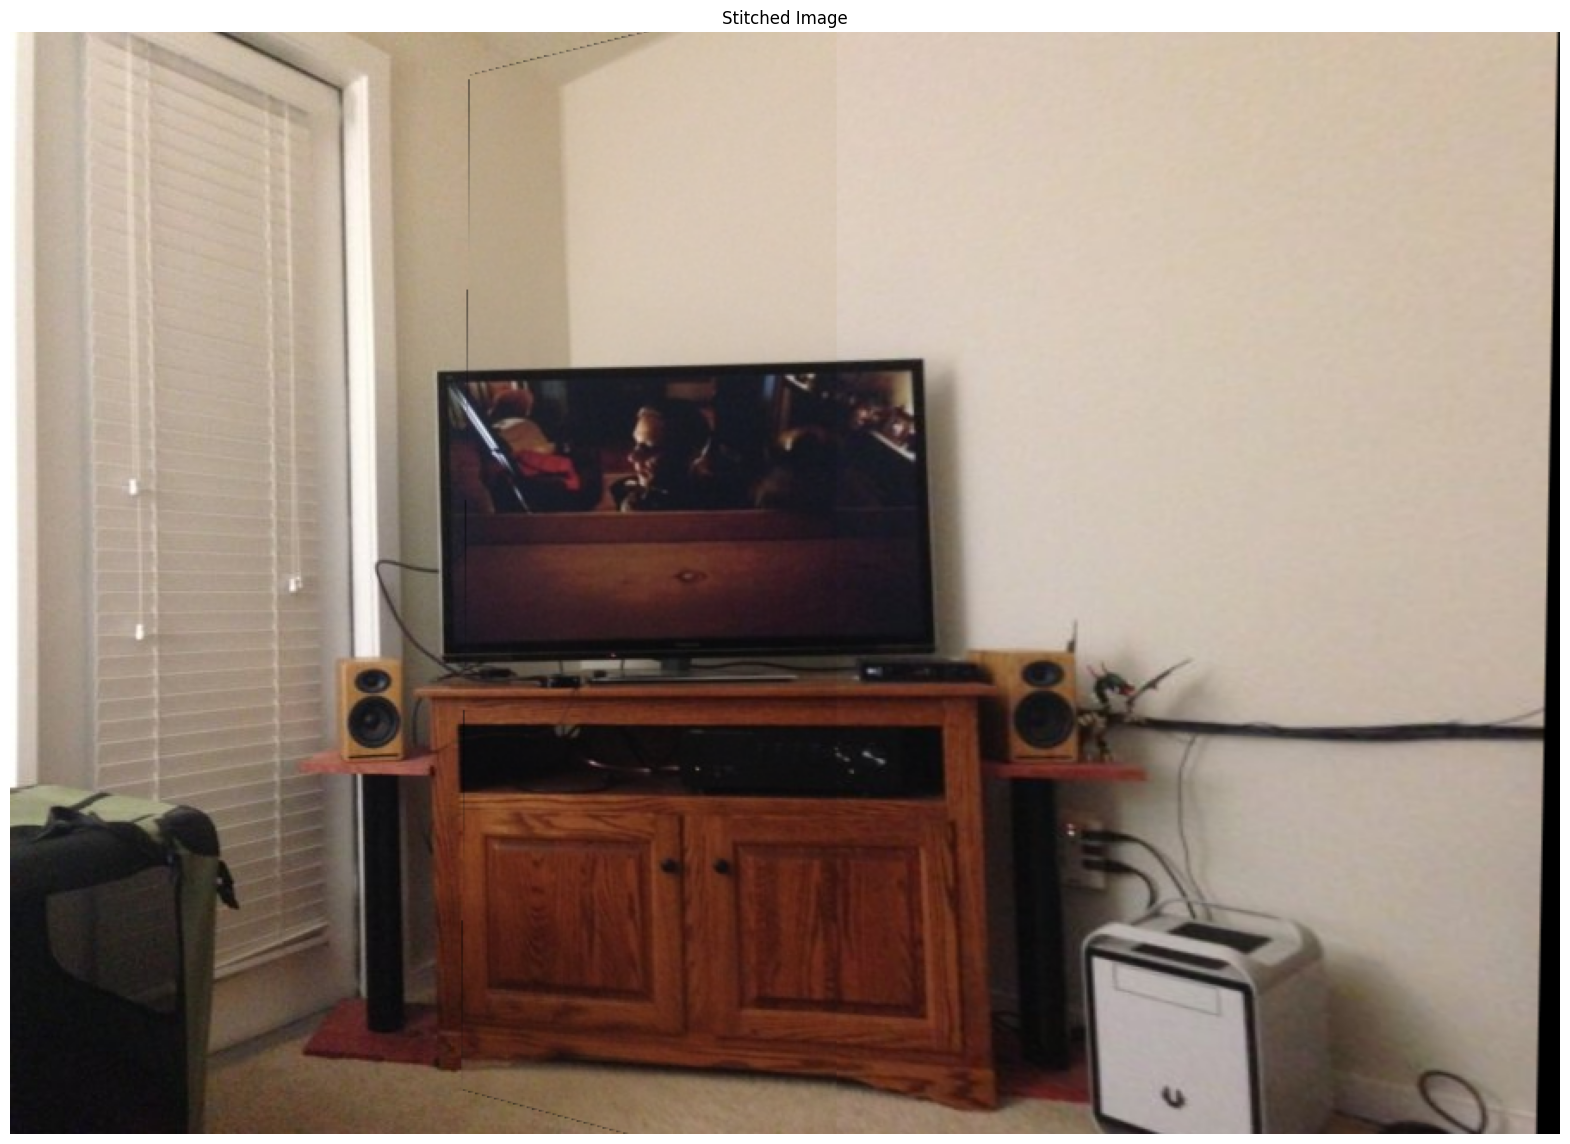

In [3]:
img1 = cv2.imread('images/1.jpg')
img2 = cv2.imread('images/2.jpg')

pts1, pts2, good_matches, kp1, kp2 = detect_and_match(img1, img2)
H, inlier_mask = compute_homography(pts1, pts2)
stitched = stitch_and_blend(img1, img2, H)

plt.figure(figsize=(20, 20))
plt.imshow(cv2.cvtColor(stitched, cv2.COLOR_BGR2RGB))
plt.title('Stitched Image')
plt.axis('off')
plt.show()

## Panorama stitching

In [4]:
def panorama_stitch(images):
    n = len(images)
    ref_idx = n // 2

    # homography between each neighbouring pair
    H_pairs = []
    for i in range(n - 1):
        pts1, pts2, _, _, _ = detect_and_match(images[i], images[i + 1])
        H, _ = compute_homography(pts1, pts2)
        H_pairs.append(H)

    # chain them so every image maps into the reference (middle) image
    H_to_ref = [None] * n
    H_to_ref[ref_idx] = np.eye(3)
    for i in range(ref_idx - 1, -1, -1):
        H_to_ref[i] = H_to_ref[i + 1] @ np.linalg.inv(H_pairs[i])
    for i in range(ref_idx + 1, n):
        H_to_ref[i] = H_to_ref[i - 1] @ H_pairs[i - 1]

    # canvas size from the warped image corners
    all_corners = []
    for i, img in enumerate(images):
        h, w = img.shape[:2]
        corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        all_corners.append(cv2.perspectiveTransform(corners, H_to_ref[i]))
    all_corners = np.concatenate(all_corners, axis=0)

    x_min, y_min = np.floor(all_corners.min(axis=0)[0]).astype(int)
    x_max, y_max = np.ceil(all_corners.max(axis=0)[0]).astype(int)
    canvas_w, canvas_h = int(x_max - x_min), int(y_max - y_min)

    offset = np.array([[1, 0, -x_min],
                       [0, 1, -y_min],
                       [0, 0, 1]], dtype=np.float64)

    # warp everything onto the canvas and average the overlaps
    canvas = np.zeros((canvas_h, canvas_w, 3), dtype=np.float32)
    weight_map = np.zeros((canvas_h, canvas_w), dtype=np.float32)

    for i, img in enumerate(images):
        warped = cv2.warpPerspective(img.astype(np.float32), offset @ H_to_ref[i], (canvas_w, canvas_h))
        mask = (warped.sum(axis=2) > 0).astype(np.float32)
        canvas += warped * mask[:, :, np.newaxis]
        weight_map += mask

    panorama = (canvas / np.maximum(weight_map, 1)[:, :, np.newaxis]).astype(np.uint8)

    # crop empty rows/columns
    gray = cv2.cvtColor(panorama, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 1, 255, cv2.THRESH_BINARY)
    rows = np.any(thresh > 0, axis=1)
    cols = np.any(thresh > 0, axis=0)

    return panorama[rows][:, cols]

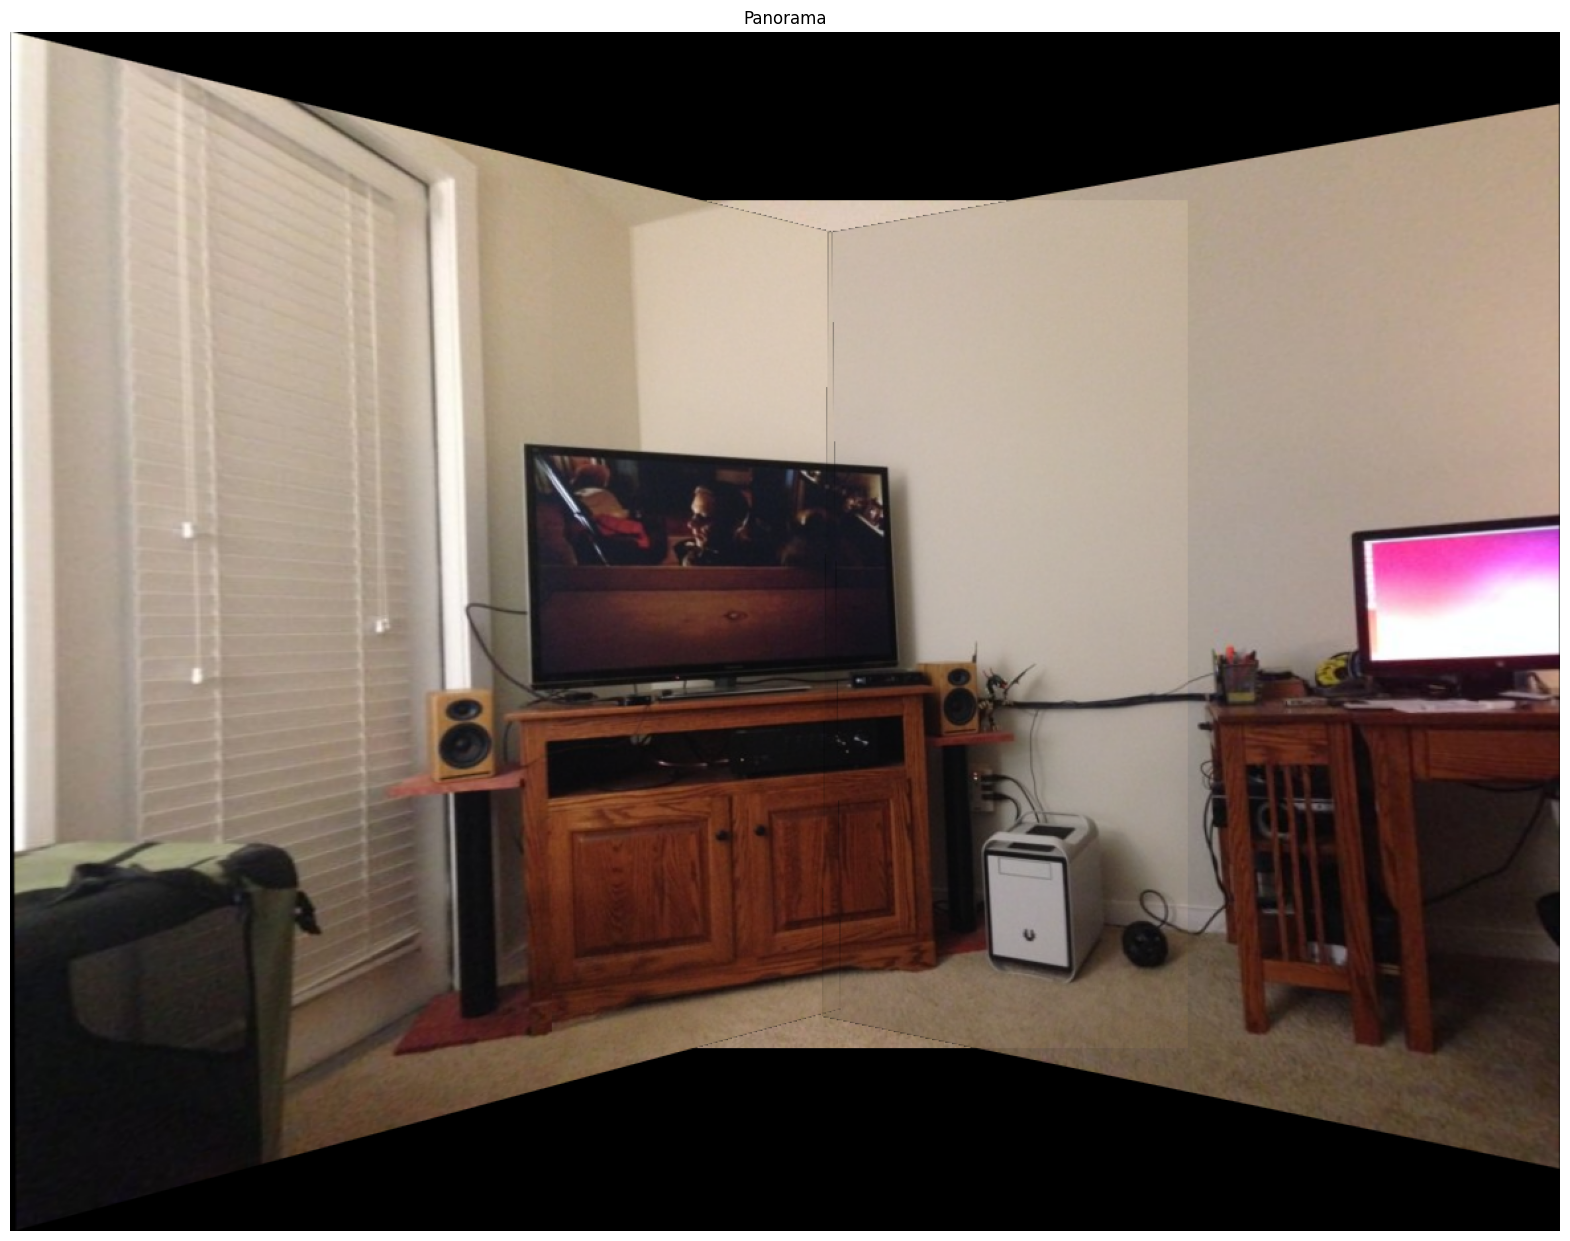

In [5]:
img_left = cv2.imread('images/1.jpg')
img_centre = cv2.imread('images/2.jpg')
img_right = cv2.imread('images/3.jpg')

panorama = panorama_stitch([img_left, img_centre, img_right])

plt.figure(figsize=(20, 20))
plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
plt.title('Panorama')
plt.axis('off')
plt.show()